# 04 Garages and sheds (Lab 8 + Assignment 5)

Find small buildings on each lot. This notebook also picks the single-family lots used in notebook 05.

**Inputs**
- `data/raw/6950/buildings/`
- `data/raw/6950/parcels/`
- `data/processed/tracts_2020.gpkg`

**Output**
- `data/processed/sheds.csv` (one row per single-family lot: house size, number and size of small buildings)
- `data/processed/6950_lots_sf.gpkg` (the single-family lots + their buildings, for notebook 05. Not committed)

Run `python musa6950/get_data.py` first. Use the geoai env.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parents[1] if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "shared"))
from common import RAW, OUT
R6 = RAW / "6950"
FIG = ROOT / "musa6950" / "docs" / "figures"
UTM = 26918   # both pilot counties are in UTM 18N, same as their NAIP tiles

## Which lots are single-family?

- Philadelphia: the PWD lot layer has a building type. Keep `bldg_desc` that starts with `DET` (detached house)
  - Rowhouses and twins (`ROW`, `S/D`, `SEMI DET`) are dropped. Microsoft merges a whole row into one outline, so the house can not be found anyway
- Cumberland: no building type in the lot file. Keep lots of 300-20,000 m2 (about 0.07-5 acres)
- Both: one main building. The biggest outline on the lot is 60-600 m2 and no other outline is over 100 m2
  - Drops vacant lots, apartments, farms with barns, and merged outlines
- An outline belongs to the lot that holds its center point

In [2]:
phl = gpd.read_file(R6 / "parcels" / "parcels_philadelphia.gpkg")
phl = phl[phl.bldg_desc.str.match(r"^DET", na=False)].copy()
phl["lot_id"] = "42101-" + phl.parcelid.astype(str)
phl["county"] = "42101"
cum = gpd.read_file(R6 / "parcels" / "parcels_cumberland.gpkg")
cum["Link"] = cum.Link.fillna(cum.GlobalID)
cum["lot_id"] = "42041-" + cum.Link + cum.groupby("Link").cumcount().map(lambda k: "" if k == 0 else f"-{k + 1}")
cum["county"] = "42041"
lots = pd.concat([phl[["lot_id", "county", "geometry"]], cum[["lot_id", "county", "geometry"]]], ignore_index=True)
lots = gpd.GeoDataFrame(lots, crs=4326).to_crs(UTM)
lots["geometry"] = lots.geometry.buffer(0)
lots["lot_m2"] = lots.area
print("candidate lots:", lots.groupby("county").size().to_dict())
lots = lots[(lots.county == "42101") | lots.lot_m2.between(300, 20000)]
print("after Cumberland size filter:", lots.groupby("county").size().to_dict())

candidate lots: {'42041': 104747, '42101': 28429}
after Cumberland size filter: {'42041': 82008, '42101': 28429}


In [3]:
bld = pd.concat([gpd.read_file(R6 / "buildings" / f"buildings_{n}.gpkg").assign(src=n) for n in ["philadelphia", "cumberland"]],
                ignore_index=True).to_crs(UTM)
bld["b_m2"] = bld.area
bld["bid"] = np.arange(len(bld))
pts = gpd.GeoDataFrame(bld[["bid", "b_m2"]], geometry=bld.geometry.representative_point(), crs=UTM)
j = gpd.sjoin(pts, lots[["lot_id", "geometry"]], predicate="within", how="inner")
print(f"{len(bld):,} outlines, {len(j):,} fall in a candidate lot")

j = j.sort_values(["lot_id", "b_m2"], ascending=[True, False])
j["rank"] = j.groupby("lot_id").cumcount()
per = j.groupby("lot_id").agg(n_buildings=("bid", "size"), house_m2=("b_m2", "first"),
                              house_bid=("bid", "first"))
second = j[j["rank"] == 1].set_index("lot_id").b_m2
per["second_m2"] = second.reindex(per.index).fillna(0)
small = j[(j["rank"] > 0) & (j.b_m2 < 60)].groupby("lot_id").b_m2.agg(["size", "sum"])
per["n_accessory"] = small["size"].reindex(per.index).fillna(0).astype(int)
per["accessory_m2"] = small["sum"].reindex(per.index).fillna(0)
lots = lots.merge(per, left_on="lot_id", right_index=True, how="left")
lots["n_buildings"] = lots.n_buildings.fillna(0).astype(int)

keep = lots.house_m2.between(60, 600) & (lots.second_m2 <= 100)
print("dropped: no building", (lots.n_buildings == 0).sum(), "| main outside 60-600 m2",
      ((lots.n_buildings > 0) & ~lots.house_m2.between(60, 600)).sum(),
      "| second building over 100 m2", (lots.house_m2.between(60, 600) & (lots.second_m2 > 100)).sum())
sf = lots[keep].copy()
print("single-family lots:", sf.groupby("county").size().to_dict())

263,744 outlines, 109,718 fall in a candidate lot


dropped: no building 19723 | main outside 60-600 m2 2848 | second building over 100 m2 3932
single-family lots: {'42041': 57664, '42101': 26270}


## Simple way first

- Biggest outline on the lot = house
- Other outlines under 60 m2 = garage or shed

In [4]:
summ = sf.groupby("county").agg(lots=("lot_id", "size"), median_lot_m2=("lot_m2", "median"),
                                median_house_m2=("house_m2", "median"),
                                share_with_small_building=("n_accessory", lambda s: (s > 0).mean()),
                                small_buildings=("n_accessory", "sum"))
print(summ.round(3).to_string())
print("\nNumber of small buildings per lot:")
print(pd.crosstab(sf.county, sf.n_accessory.clip(upper=3).astype(str).replace({"3": "3+"}), normalize="index").round(3))

         lots  median_lot_m2  median_house_m2  share_with_small_building  small_buildings
county                                                                                   
42041   57664       1425.387          187.136                      0.088           5320.0
42101   26270        637.213          141.137                      0.082           2214.0

Number of small buildings per lot:
n_accessory    0.0    1.0    2.0  3.0
county                               
42041        0.912  0.083  0.004  0.0
42101        0.918  0.079  0.002  0.0


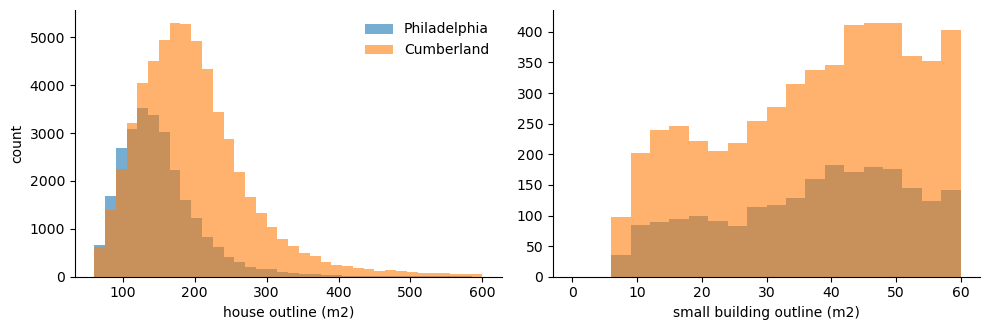

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
for c, name in [("42101", "Philadelphia"), ("42041", "Cumberland")]:
    s = sf[sf.county == c]
    ax[0].hist(s.house_m2, bins=np.arange(60, 610, 15), alpha=0.6, label=name)
    acc = j[(j["rank"] > 0) & (j.b_m2 < 60) & j.lot_id.isin(s.lot_id)].b_m2
    ax[1].hist(acc, bins=np.arange(0, 61, 3), alpha=0.6, label=name)
ax[0].set_xlabel("house outline (m2)"); ax[1].set_xlabel("small building outline (m2)")
ax[0].set_ylabel("count"); ax[0].legend(frameon=False)
for a in ax:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(FIG / "04_outline_sizes.png", dpi=110)
plt.show()

## Save

- `sheds.csv`: lot_id, county, lot_m2, house_m2, n_accessory, accessory_m2
- `6950_lots_sf.gpkg`: lots + all their outlines (for the backyard in notebook 05)

In [6]:
tracts = gpd.read_file(OUT / "tracts_2020.gpkg").to_crs(UTM)
cen = gpd.GeoDataFrame(sf[["lot_id"]], geometry=sf.geometry.representative_point(), crs=UTM)
t = gpd.sjoin(cen, tracts[["GEOID", "geometry"]], predicate="within", how="left").drop_duplicates("lot_id")
sf["GEOID"] = t.set_index("lot_id").GEOID.reindex(sf.lot_id).values
print("lots without a tract:", sf.GEOID.isna().sum())
sf[["lot_id", "county", "GEOID", "lot_m2", "house_m2", "n_accessory", "accessory_m2"]].round(1).to_csv(OUT / "sheds.csv", index=False)

b_sf = bld.merge(j[["bid", "lot_id", "rank"]], on="bid")
b_sf = b_sf[b_sf.lot_id.isin(sf.lot_id)][["lot_id", "rank", "b_m2", "geometry"]]
sf[["lot_id", "county", "GEOID", "lot_m2", "house_m2", "n_accessory", "accessory_m2", "geometry"]].to_file(OUT / "6950_lots_sf.gpkg", layer="lots")
b_sf.to_file(OUT / "6950_lots_sf.gpkg", layer="buildings")
print(len(sf), "lots,", len(b_sf), "outlines saved")

lots without a tract: 0


83934 lots, 96460 outlines saved


## YOLO (optional)

**OPTIONAL. Not done.**

- Plan: label 150-300 sheds in LabelMe, convert with load_labelme() from Assignment 5, fine-tune, then compare with the outlines
- Skipped for now. There are no shed labels yet, and making them is hand work
- The outline method above is what notebook 05 uses
- ultralytics is AGPL-3.0. If Ye adds this later, keep it in this notebook only (`requirements-yolo.txt`)

In [7]:
# Optional, for Ye. Left empty on purpose. Needs hand-made shed labels first.